In [1]:
# !pip install tokenizers      # Colab 需要
import os, json
import matplotlib.pyplot as plt

DATA_DIR = "."     # shakespeare_train.txt 所在資料夾
OUT_DIR  = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

train_text = open(os.path.join(DATA_DIR, "shakespeare_train.txt"), encoding="utf-8").read()
n_chars = len(train_text)
print("總字元數:", n_chars)
print(repr(train_text[:200]))

總字元數: 4351312
'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you'


In [2]:
chars = sorted(set(train_text))
char_vocab, char_tokens = len(chars), n_chars        # 一個字元 = 一個 token
print("char vocab size:", char_vocab)
print("char tokens    :", char_tokens)
print("字表:", "".join(c if c.isprintable() and c != " " else repr(c) for c in chars))

char vocab size: 67
char tokens    : 4351312
字表: '\n'' '!$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz


In [3]:
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers

def train_bpe(text, vocab_size):
    tk = Tokenizer(models.BPE())
    tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tk.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, show_progress=False,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tk.train_from_iterator(text.splitlines(keepends=True), trainer)
    return tk

results = {"char": dict(vocab_size=char_vocab, num_tokens=char_tokens, ratio=n_chars / char_tokens)}
bpe_tk = {}
for v in [1000, 2000]:
    tk = train_bpe(train_text, v)
    ids = tk.encode(train_text).ids
    bpe_tk[v] = tk
    results[f"bpe_{v}"] = dict(vocab_size=tk.get_vocab_size(), num_tokens=len(ids), ratio=n_chars / len(ids))
    print(f"BPE-{v}: round-trip decode == original ?", tk.decode(ids) == train_text)

# (2) 壓縮率表格
print(f"\n總字元數 = {n_chars:,}\n")
print("| Tokenizer | Vocab size | #Tokens | Compression ratio (chars / token) |")
print("|---|---|---|---|")
for k, r in results.items():
    print(f"| {k} | {r['vocab_size']} | {r['num_tokens']:,} | {r['ratio']:.3f} |")
json.dump(dict(num_chars=n_chars, results=results), open(os.path.join(OUT_DIR, "q1_tokenization.json"), "w"), indent=2)

BPE-1000: round-trip decode == original ? True
BPE-2000: round-trip decode == original ? True

總字元數 = 4,351,312

| Tokenizer | Vocab size | #Tokens | Compression ratio (chars / token) |
|---|---|---|---|
| char | 67 | 4,351,312 | 1.000 |
| bpe_1000 | 1000 | 1,842,276 | 2.362 |
| bpe_2000 | 2000 | 1,588,622 | 2.739 |


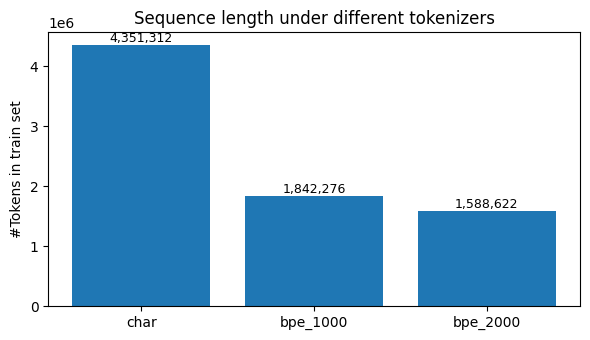

BPE-1000 切詞 (27 tokens vs 57 chars):
  ['RO', 'M', 'E', 'O', ':', '\n', 'But', ' so', 'f', 't', ',', ' what', ' li', 'ght', ' th', 'r', 'ough', ' y', 'ond', 'er', ' w', 'ind', 'ow', ' bre', 'ak', 's', '?']
  最長的 token: ['GLOUCESTER', ' friends', ' nothing', 'FALSTAFF', ' brother', ' thought', ' should', ' father', ' better', ' gentle', ' before', 'aughter', ' honour', ' master', ' myself'] 

BPE-2000 切詞 (17 tokens vs 57 chars):
  ['ROMEO', ':', '\n', 'But', ' so', 'ft', ',', ' what', ' light', ' through', ' y', 'onder', ' wind', 'ow', ' break', 's', '?']
  最長的 token: [' ANDRONICUS', ' therefore', ' Gentleman', 'ANTIPHOLUS', ' VINCENTIO', 'GLOUCESTER', ' gentleman', ' remember', ' thoughts', 'Messenger', ' pleasure', ' yourself', 'PETRUCHIO', ' thousand', 'CLEOPATRA'] 



In [4]:
names = list(results.keys()); counts = [results[k]["num_tokens"] for k in names]
plt.figure(figsize=(6, 3.5))
bars = plt.bar(names, counts)
for b, c in zip(bars, counts): plt.text(b.get_x() + b.get_width() / 2, c, f"{c:,}", ha="center", va="bottom", fontsize=9)
plt.ylabel("#Tokens in train set"); plt.title("Sequence length under different tokenizers")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "q1_token_counts.png"), dpi=200); plt.show()

sample = "ROMEO:\nBut soft, what light through yonder window breaks?"
for v, tk in bpe_tk.items():
    pieces = [tk.decode([i]) for i in tk.encode(sample).ids]
    print(f"BPE-{v} 切詞 ({len(pieces)} tokens vs {len(sample)} chars):\n  {pieces}")
    vocab = tk.get_vocab()
    longest = sorted(vocab.items(), key=lambda kv: -len(tk.decode([kv[1]])))[:15]
    print("  最長的 token:", [tk.decode([i]) for _, i in longest], "\n")